In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Classification Evaluation Metrics

## 1. Why Do We Need Evaluation Metrics?

After training a classification model, we need to evaluate how well it predicts unseen data.

Accuracy alone may not be sufficient, especially when one class is much more common than the other.

We will use five important metrics:

- Accuracy
- Confusion Matrix
- Precision
- Recall
- F1-score

## 2. Confusion Matrix

A confusion matrix compares actual labels with predicted labels.

| | Predicted Positive | Predicted Negative |
|---|---|---|
| Actual Positive | True Positive (TP) | False Negative (FN) |
| Actual Negative | False Positive (FP) | True Negative (TN) |

**True Positive (TP):** The model correctly predicts a positive class.

**True Negative (TN):** The model correctly predicts a negative class.

**False Positive (FP):** The model predicts positive, but the actual class is negative.

**False Negative (FN):** The model predicts negative, but the actual class is positive.

## 3. Accuracy

Accuracy measures the proportion of all predictions that are correct.

Accuracy = (TP + TN) / (TP + TN + FP + FN)

## 4. Precision

Precision measures how many predicted positive cases are actually positive.

Precision = TP / (TP + FP)

High precision means fewer false positive predictions.

## 5. Recall

Recall measures how many actual positive cases the model correctly identifies.

Recall = TP / (TP + FN)

High recall means fewer actual positive cases are missed.

## 6. F1-score

The F1-score is the harmonic mean of precision and recall.

F1-score = 2 × (Precision × Recall) / (Precision + Recall)

It balances precision and recall, making it useful when both matter.

## 7. Important Observation

In fraud detection, accuracy can be misleading because fraudulent transactions are rare.

A model that predicts every transaction as legitimate can achieve very high accuracy while detecting no fraud at all.

Therefore, we should examine the confusion matrix, precision, recall, and F1-score together.

In [2]:
import glob
import pandas  as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

csv_files = glob.glob("/kaggle/input/**/*.csv", recursive=True)
print(csv_files)

['/kaggle/input/datasets/mlg-ulb/creditcardfraud/creditcard.csv']


In [7]:
df = pd.read_csv("/kaggle/input/datasets/mlg-ulb/creditcardfraud/creditcard.csv")

df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [8]:
print("Dataset shape:", df.shape)
print(df["Class"].value_counts())
print(df.isnull().sum().sum())

Dataset shape: (284807, 31)
Class
0    284315
1       492
Name: count, dtype: int64
0


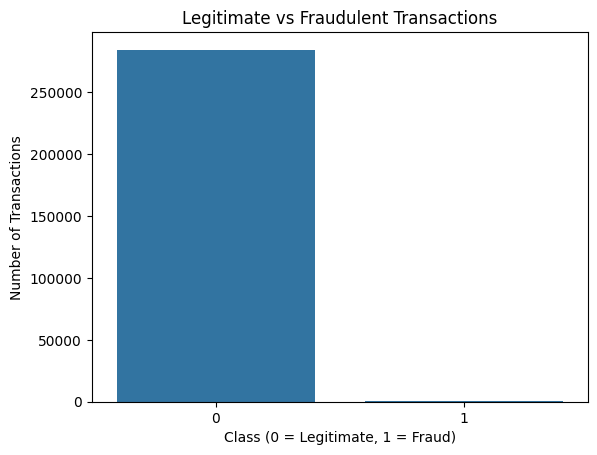

In [9]:
sns.countplot(data=df, x="Class")

plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.show()

In [10]:
X = df.drop(columns=["Class"])
y = df["Class"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (284807, 30)
y shape: (284807,)


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 227845
Testing samples: 56962

Training class distribution:
Class
0    227451
1       394
Name: count, dtype: int64

Testing class distribution:
Class
0    56864
1       98
Name: count, dtype: int64


In [14]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Training the Classification Model

Logistic Regression estimates the probability that a transaction belongs to a particular class.

We train the model using the training dataset and evaluate it on the test dataset.

Initially, we will use the default class weighting to establish a baseline. Because fraud is rare, the model may miss some fraudulent transactions even if its accuracy is high.

In [15]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [16]:
y_pred = model.predict(X_test_scaled)

print("Actual labels:    ", y_test.iloc[:10].to_numpy())
print("Predicted labels: ", y_pred[:10])

Actual labels:     [0 0 0 0 0 0 0 0 0 0]
Predicted labels:  [0 0 0 0 0 0 0 0 0 0]


## Confusion Matrix

A confusion matrix compares actual labels with predicted labels.

| | Predicted 0 | Predicted 1 |
|---|---|---|
| Actual 0 | True Negative (TN) | False Positive (FP) |
| Actual 1 | False Negative (FN) | True Positive (TP) |

- **TN:** Legitimate transaction correctly identified.
- **FP:** Legitimate transaction incorrectly flagged as fraud.
- **FN:** Fraudulent transaction incorrectly classified as legitimate.
- **TP:** Fraudulent transaction correctly detected.

The confusion matrix helps us understand the types of errors made by our model.

In [18]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[56851    13]
 [   36    62]]


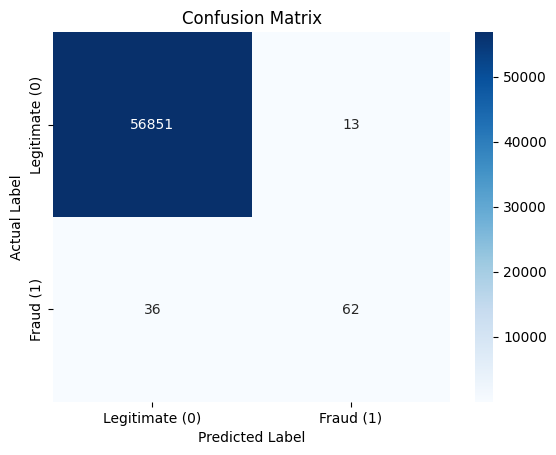

In [19]:
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate (0)", "Fraud (1)"],
    yticklabels=["Legitimate (0)", "Fraud (1)"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()

In [22]:
tn, fp, fn, tp = cm.ravel()

print("True Negative (TN):", tn)
print("False Positive (FP):", fp)
print("False Negative (FN):", fn)
print("True Positive (TP):", tp)

True Negative (TN): 56851
False Positive (FP): 13
False Negative (FN): 36
True Positive (TP): 62


## Accuracy

Accuracy measures the proportion of all predictions that are correct.

Formula:

Accuracy = (TP + TN) / (TP + TN + FP + FN)

A high accuracy means that most predictions are correct overall.

**Limitation:** In an imbalanced dataset, accuracy can be misleading. A model can predict every transaction as legitimate and still achieve very high accuracy while detecting no fraud.

In [23]:
accuracy = (tp + tn) / (tp + tn + fp + fn)

print("Accuracy:", accuracy)
print("Accuracy percentage:", accuracy * 100, "%")

Accuracy: 0.9991397773954567
Accuracy percentage: 99.91397773954567 %


In [24]:
print("Sklearn Accuracy:", accuracy_score(y_test, y_pred))

Sklearn Accuracy: 0.9991397773954567


## Precision

Precision tells us how many transactions predicted as fraudulent were actually fraudulent.

Formula:

Precision = TP / (TP + FP)

High precision means fewer false alarms.

For example, if the model flags 100 transactions as fraudulent and 80 are genuinely fraudulent, precision is 80%.

Precision is important when investigating false fraud alerts is costly.

In [25]:
precision = tp / (tp + fp) if (tp + fp) > 0 else 0

print("Precision:", precision)

Precision: 0.8266666666666667


In [ ]:
print("Sklearn Precision:", precision_score(y_test, y_pred, zero_division=0))

## Recall

Recall measures how many actual fraudulent transactions the model correctly identifies.

Formula:

Recall = TP / (TP + FN)

High recall means fewer fraudulent transactions are missed.

For example, if there are 100 actual fraudulent transactions and the model detects 90, recall is 90%.

Recall is especially important when missing a fraudulent transaction has a high cost.

In [26]:
recall = tp / (tp + fn) if (tp + fn) > 0 else 0

print("Recall:", recall)

Recall: 0.6326530612244898


In [29]:
f1 = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0
    else 0
)

print("F1-score:", f1)

F1-score: 0.7167630057803468


In [35]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.83      0.63      0.72        98

    accuracy                           1.00     56962
   macro avg       0.91      0.82      0.86     56962
weighted avg       1.00      1.00      1.00     56962

